# Figure 7 — Atmospheric circulation and cold-air outbreak composites by Greenland Sea sea-ice extent

Standalone notebook for manuscript **Figure 7** only. Rows: winters in the upper
(High) and lower (Low) quartile of Greenland Sea winter-maximum sea-ice extent,
and their difference (High − Low). Columns: MSLP anomaly with 10 m wind anomaly
vectors; 2 m air temperature anomaly; cold-air outbreak (CAO) index anomaly.
Panels are lettered a–i row-wise (High a–c, Low d–f, Diff g–i).

Extracted from `compute_spatial_composites_eof.ipynb` (ERA5 / GS_SIE path only,
`ICE_METRIC='max'`, `SEASON_TAG=''`), with the same loaders, baseline, CAO
definition, classification, compositing and plotting, so the figure reproduces
the version in the manuscript. Climate-index, EOF and GLORYS12 composites are
not produced here.

In [1]:
"""
Figure 07 — ERA5 composites by Greenland Sea winter-maximum sea-ice extent

Outputs
-------
  ./outputs/figures/figure_07_atmospheric_composites.png                       (600 dpi)
  ./outputs/processed_data/figure_07_composites/era5_monthly.nc                 (stage-1 cache)
  ./outputs/processed_data/figure_07_composites/composite_stats_era5_GS_SIE.nc
  ./outputs/processed_data/figure_07_composites/composite_classification_GS_SIE.csv
  ./outputs/methods/figure_07_methodology.md

Version:       1.0.0
Last Modified: 2026-10-13
Author:        C. Barrell
"""

import sys
import glob
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy import stats
import metpy.calc as mpcalc
from metpy.units import units

warnings.filterwarnings("ignore")

# ============================================================================
# CONFIGURATION
# ============================================================================

# False -> reuse the stage-1 ERA5 cache (this notebook's own, else the shared
# one written by compute_spatial_composites_eof.ipynb). True -> rebuild from
# the raw ERA5 files (slow).
REPROCESS = False
SAVE_DATA = True

sys.path.append('..')
try:
    from utils.logger import get_logger
    logger = get_logger('figure_07', config_path='../config.yaml')
except Exception:
    logger = logging.getLogger('figure_07')
    logging.basicConfig(level=logging.INFO)

# --- Data sources ---
ERA5_PATTERN = '../../era5/era5_*_Arctic.nc'
ICE_NC  = './outputs/processed_data/osisaf_sii_v3/osisaf_sii_v3_all_regions.nc'
ICE_VAR = 'ice_extent_greenland_monthly'

# --- ERA5 fields (only what Figure 7 needs) ---
ERA5_VARS_SFC = ['msl', 'u10', 'v10', 't2m', 'skt', 'siconc']
PRESSURE_LEVEL_DIM = 'pressure_level'
CAO_PRESSURE_LEVEL = 850          # hPa, as figure_06's calculate_cao_index()
ERA5_VARS_PL = [('t', CAO_PRESSURE_LEVEL, f't{CAO_PRESSURE_LEVEL}')]
SIC_THRESHOLD = 0.15              # CAO masked where siconc >= this; ice-edge contour level
ERA5_DOMAIN = {'lon': (-90.0, 40.0), 'lat': (50.0, 88.0)}
ERA5_COARSEN_DEG = None           # None = native resolution

TIME_DIM, LAT_DIM, LON_DIM = 'time', 'latitude', 'longitude'

# --- Baseline, season and classification ---
# Anomaly baseline: None = full ERA5 record (each calendar month's mean over
# every year available). A (start, end) tuple restricts it, e.g. (1993, 2023)
# reproduces the earlier fixed baseline shared with the GLORYS12 composites.
BASELINE_YEARS = None
MIN_BASELINE_YEARS = 15
WINTER_MONTHS = [10, 11, 12, 1, 2, 3, 4]   # ONDJFMA, winters labelled by year of ending
QUANTILE = 0.25                            # upper/lower quartile -> High/Low
SIE_LABEL = 'GS_SIE'                       # classification by winter-MAXIMUM extent

# --- Figure ---
ERA5_COLUMNS = [
    ('msl', 'MSLP anomaly (hPa)', 0.01),
    ('t2m', 'T2m anomaly (K)', 1.0),
    ('cao', 'CAO index anomaly (K)', 1.0),
]
# Style matched to the other manuscript figures: '(a) Title' left-aligned
# panel titles, colourbar label/tick sizes as Fig. 8, lat/lon labels on the
# outer map panels as Figs 1 and 5. Rows are identified in the titles.
TITLE_FONTSIZE = 10
CBAR_LABEL_FONTSIZE = 8
CBAR_TICK_FONTSIZE = 7
GRID_LABEL_FONTSIZE = 7
QUIVERKEY_FONTSIZE = 7
ROW_TITLES = {'mean_high': 'High', 'mean_low': 'Low', 'diff': 'High \u2013 Low'}
COLUMN_TITLES = {'msl': 'MSLP and 10 m wind', 't2m': 'T2m', 'cao': 'CAO index'}
WIND_QUIVERKEY_SPEED = 1.0   # m s-1 reference arrow
DPI = 600

# --- Outputs ---
OUT_FIG  = Path('./outputs/figures')
OUT_DATA = Path('./outputs/processed_data/figure_07_composites')
OUT_METH = Path('./outputs/methods')
for d in (OUT_FIG, OUT_DATA, OUT_METH):
    d.mkdir(parents=True, exist_ok=True)
FIG_PATH = OUT_FIG / 'figure_07_atmospheric_composites.png'

ERA5_CACHE = OUT_DATA / 'era5_monthly.nc'
SHARED_ERA5_CACHE = Path('./outputs/processed_data/spatial_composites/era5_monthly_baseline.nc')

logger.info(f"Figure 7: BASELINE_YEARS={BASELINE_YEARS}, QUANTILE={QUANTILE}, "
            f"months={WINTER_MONTHS}, classification=winter-max {SIE_LABEL}")

INFO:figure_07:Figure 7: BASELINE_YEARS=None, QUANTILE=0.25, months=[10, 11, 12, 1, 2, 3, 4], classification=winter-max GS_SIE


## Section 1 — ERA5 monthly fields and CAO index

In [2]:
def standardize_era5(ds):
    if 'valid_time' in ds.variables or 'valid_time' in ds.dims:
        ds = ds.rename({'valid_time': TIME_DIM})
    if 'expver' in ds.dims:
        ds = ds.isel(expver=0, drop=True)
    elif 'expver' in ds.coords:
        ds = ds.drop_vars('expver')
    return ds


def crop_to_domain(ds, domain, lat_dim=LAT_DIM, lon_dim=LON_DIM):
    if lon_dim in ds.coords and float(np.nanmax(ds[lon_dim].values)) > 180.0:
        ds = ds.assign_coords({lon_dim: (((ds[lon_dim] + 180) % 360) - 180)})
        ds = ds.sortby(lon_dim)
    lat_ok = ((ds[lat_dim] >= domain['lat'][0]) & (ds[lat_dim] <= domain['lat'][1])).values
    lon_ok = ((ds[lon_dim] >= domain['lon'][0]) & (ds[lon_dim] <= domain['lon'][1])).values
    return ds.isel({lat_dim: np.where(lat_ok)[0], lon_dim: np.where(lon_ok)[0]})


def load_era5_monthly(pattern, domain, vars_sfc, vars_pl, coarsen_deg):
    """Stream raw ERA5 files one at a time, cropping before loading."""
    files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No ERA5 files matched {pattern}")
    logger.info(f"Streaming {len(files)} ERA5 file(s) from {pattern}")

    pieces, factor = [], None
    for k, fp in enumerate(files):
        with xr.open_dataset(fp, chunks={TIME_DIM: 24}) as ds_raw:
            ds = crop_to_domain(standardize_era5(ds_raw), domain)
            keep = {v: ds[v] for v in vars_sfc if v in ds.data_vars}
            missing = [v for v in vars_sfc if v not in ds.data_vars]
            if missing and k == 0:
                logger.warning(f"ERA5 variables not found in {Path(fp).name}: {missing}")
            for raw_var, plevel, out_name in vars_pl:
                if raw_var in ds.data_vars and PRESSURE_LEVEL_DIM in ds[raw_var].dims:
                    keep[out_name] = ds[raw_var].sel(
                        {PRESSURE_LEVEL_DIM: plevel}, method='nearest'
                    ).drop_vars(PRESSURE_LEVEL_DIM, errors='ignore')
            if not keep:
                continue
            sub = xr.Dataset(keep)
            if sub.sizes.get(TIME_DIM, 0) > 1:
                dt_days = np.median(np.diff(sub[TIME_DIM].values)
                                    .astype('timedelta64[h]').astype(float)) / 24.0
                if dt_days < 27:
                    sub = sub.resample({TIME_DIM: 'MS'}).mean()
            if coarsen_deg is not None:
                if factor is None:
                    dlat = float(np.abs(np.diff(sub[LAT_DIM].values)).mean())
                    factor = max(1, int(round(coarsen_deg / dlat)))
                if factor > 1:
                    sub = sub.coarsen({LAT_DIM: factor, LON_DIM: factor}, boundary='trim').mean()
            pieces.append(sub.load())

    out = xr.concat(pieces, dim=TIME_DIM).sortby(TIME_DIM)
    out = out.sel({TIME_DIM: ~out.indexes[TIME_DIM].duplicated()})
    logger.info(f"ERA5 monthly: {dict(out.sizes)}, "
                f"{str(out[TIME_DIM].values[0])[:7]} to {str(out[TIME_DIM].values[-1])[:7]}")
    return out


needed = ERA5_VARS_SFC + [o for _, _, o in ERA5_VARS_PL]
if REPROCESS:
    era5 = load_era5_monthly(ERA5_PATTERN, ERA5_DOMAIN, ERA5_VARS_SFC, ERA5_VARS_PL,
                             ERA5_COARSEN_DEG)
    if SAVE_DATA:
        era5.to_netcdf(ERA5_CACHE)
        logger.info(f"Saved: {ERA5_CACHE}")
else:
    cache = ERA5_CACHE if ERA5_CACHE.exists() else SHARED_ERA5_CACHE
    if not cache.exists():
        raise FileNotFoundError(f"No ERA5 cache at {ERA5_CACHE} or {SHARED_ERA5_CACHE} "
                                f"-- set REPROCESS=True to build it from raw files.")
    era5 = xr.open_dataset(cache)
    era5 = era5[[v for v in needed if v in era5.data_vars]].load()
    logger.info(f"Loaded ERA5 cache {cache}: {dict(era5.sizes)}")

missing = [v for v in needed if v not in era5.data_vars]
if missing:
    raise KeyError(f"ERA5 fields {missing} missing -- set REPROCESS=True to rebuild the cache.")


def compute_cao_index(ds_era, pressure_level, t_pl_varname, sic_threshold):
    """CAO index = theta_skin - theta(p), as figure_06's calculate_cao_index(),
    computed on raw fields and masked to siconc < sic_threshold (open ocean)."""
    T_plev = ds_era[t_pl_varname]
    theta_plev = xr.DataArray(
        mpcalc.potential_temperature(pressure_level * units.hPa,
                                     T_plev.values * units.kelvin).magnitude,
        coords=T_plev.coords, dims=T_plev.dims)
    cao = (ds_era['skt'] - theta_plev).where(ds_era['siconc'] < sic_threshold)
    cao.attrs.update(long_name='Cold-air outbreak index (theta_skin - theta_850)', units='K')
    logger.info(f"CAO index computed at {pressure_level} hPa, masked to siconc < {sic_threshold:.0%}")
    return ds_era.assign(cao=cao)


era5 = compute_cao_index(era5, CAO_PRESSURE_LEVEL, f't{CAO_PRESSURE_LEVEL}', SIC_THRESHOLD)

INFO:argopy.stores.ArgoFloat:Using ONLINE Argo Float implementation
INFO:httpx:HTTP Request: GET https://raw.githubusercontent.com/IrishMarineInstitute/awesome-erddap/master/erddaps.json "HTTP/1.1 200 OK"
INFO:figure_07:Loaded ERA5 cache outputs/processed_data/spatial_composites/era5_monthly_baseline.nc: {'time': 571, 'latitude': 153, 'longitude': 521}
INFO:figure_07:CAO index computed at 850 hPa, masked to siconc < 15%


## Section 2 — Anomalies relative to the full-record climatology

Per-calendar-month climatology over the full ERA5 record (`BASELINE_YEARS = None`;
set a (start, end) tuple to restrict it), subtracted from every winter month.

In [3]:
def compute_baseline_climatology(ds, baseline_years, months, min_years=MIN_BASELINE_YEARS):
    yrs = np.unique(ds[TIME_DIM].dt.year.values)
    if baseline_years is None:            # full record
        baseline_years = (int(yrs.min()), int(yrs.max()))
    avail = np.array([y for y in range(baseline_years[0], baseline_years[1] + 1) if y in yrs])
    if len(avail) < min_years:
        raise ValueError(f"Only {len(avail)} baseline years available (need >= {min_years}).")
    sel = ds.sel({TIME_DIM: ds[TIME_DIM].dt.year.isin(avail) & ds[TIME_DIM].dt.month.isin(months)})
    return sel.groupby(f'{TIME_DIM}.month').mean(TIME_DIM), avail


def anomalise_fixed_baseline(ds, clim, months):
    sel = ds.sel({TIME_DIM: ds[TIME_DIM].dt.month.isin(months)})
    return (sel.groupby(f'{TIME_DIM}.month') - clim).drop_vars('month', errors='ignore')


era5_clim, baseline_used = compute_baseline_climatology(era5, BASELINE_YEARS, WINTER_MONTHS)
era5_anom = anomalise_fixed_baseline(era5, era5_clim, WINTER_MONTHS)
logger.info(f"Baseline years used: {baseline_used.min()}-{baseline_used.max()} (n={len(baseline_used)})")

INFO:figure_07:Baseline years used: 1979-2026 (n=48)


## Section 3 — High/Low classification by winter-maximum Greenland Sea ice extent

Winter-year maximum of monthly OSI SAF extent (complete ONDJFMA winters only),
restricted to winters with complete ERA5 coverage; upper/lower quartile → High/Low.

In [4]:
def assign_winter_year(time_index):
    yrs = np.asarray(time_index.year, dtype=int).copy()
    yrs[np.asarray(time_index.month) >= 10] += 1
    return yrs


def winter_year_max_series(s, months=WINTER_MONTHS):
    s = s[s.index.month.isin(months)]
    wy = assign_winter_year(s.index)
    counts = pd.Series(1, index=wy).groupby(level=0).sum()
    complete = counts[counts >= len(months)].index
    out = s.groupby(wy).max()
    out.index.name = 'year'
    return out.loc[out.index.isin(complete)]


def available_winter_years(ds, months=WINTER_MONTHS):
    times = pd.to_datetime(ds[TIME_DIM].values)
    times = times[np.isin(times.month, months)]
    counts = pd.Series(1, index=assign_winter_year(times)).groupby(level=0).sum()
    return set(counts[counts >= len(months)].index)


ice_ds = xr.open_dataset(ICE_NC)
if ICE_VAR not in ice_ds.data_vars:
    raise KeyError(f"'{ICE_VAR}' not in {ICE_NC}. Available: {sorted(ice_ds.data_vars)}")
ice_s = ice_ds[ICE_VAR].to_series().dropna()
ice_s.index = pd.to_datetime(ice_s.index)

sie_max = winter_year_max_series(ice_s)
era5_years = available_winter_years(era5_anom)
sie_max = sie_max[sie_max.index.isin(era5_years)]

lo_thr, hi_thr = sie_max.quantile(QUANTILE), sie_max.quantile(1 - QUANTILE)
high_years = sorted(sie_max[sie_max >= hi_thr].index)
low_years = sorted(sie_max[sie_max <= lo_thr].index)
logger.info(f"[{SIE_LABEL}] {len(sie_max)} winters {sie_max.index.min()}-{sie_max.index.max()}; "
            f"High n={len(high_years)}: {high_years}; Low n={len(low_years)}: {low_years}")

if SAVE_DATA:
    pd.DataFrame(
        [{'year': y, 'group': 'high', 'sie_max': sie_max[y]} for y in high_years]
        + [{'year': y, 'group': 'low', 'sie_max': sie_max[y]} for y in low_years]
    ).to_csv(OUT_DATA / 'composite_classification_GS_SIE.csv', index=False)

INFO:figure_07:[GS_SIE] 45 winters 1980-2026; High n=12: [1980, 1981, 1982, 1983, 1985, 1987, 1989, 1990, 1996, 1997, 1998, 2001]; Low n=12: [1994, 1999, 2003, 2006, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022]


## Section 4 — Composites and Welch's t-test

Each field is reduced to one winter-year mean first, so the sample unit for the
Welch's t-test is winters, not months.

In [5]:
def field_to_winter_year_means(da, months=WINTER_MONTHS):
    sel = da.sel({TIME_DIM: da[f'{TIME_DIM}.month'].isin(months)})
    sel = sel.assign_coords(winter_year=(TIME_DIM, assign_winter_year(pd.to_datetime(sel[TIME_DIM].values))))
    counts = sel.groupby('winter_year').count(TIME_DIM)
    return sel.groupby('winter_year').mean(TIME_DIM).where(counts >= len(months))


def welch_ttest_vectorized(a, b, axis=0):
    na, nb = np.sum(np.isfinite(a), axis=axis), np.sum(np.isfinite(b), axis=axis)
    ma, mb = np.nanmean(a, axis=axis), np.nanmean(b, axis=axis)
    va, vb = np.nanvar(a, axis=axis, ddof=1), np.nanvar(b, axis=axis, ddof=1)
    se2 = va / na + vb / nb
    with np.errstate(invalid='ignore', divide='ignore'):
        tstat = (ma - mb) / np.sqrt(se2)
        df = se2 ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
    pvalue = np.full(tstat.shape, np.nan)
    ok = np.isfinite(tstat) & np.isfinite(df) & (df > 0)
    pvalue[ok] = 2 * stats.t.sf(np.abs(tstat[ok]), df[ok])
    return tstat, pvalue


def composite_high_low(da, high_years, low_years):
    yearly = field_to_winter_year_means(da)
    have = set(int(y) for y in yearly['winter_year'].values)
    hy, ly = [y for y in high_years if y in have], [y for y in low_years if y in have]
    if len(hy) < len(high_years) or len(ly) < len(low_years):
        logger.warning(f"[{da.name}] only {len(hy)}/{len(high_years)} High and "
                       f"{len(ly)}/{len(low_years)} Low winters available")
    hs, ls = yearly.sel(winter_year=hy).values, yearly.sel(winter_year=ly).values
    _, p = welch_ttest_vectorized(hs, ls)
    mh, ml = np.nanmean(hs, axis=0), np.nanmean(ls, axis=0)
    return {'mean_high': mh, 'mean_low': ml, 'diff': mh - ml, 'pvalue': p,
            'n_high': len(hy), 'n_low': len(ly),
            'lat': yearly[LAT_DIM].values, 'lon': yearly[LON_DIM].values}


composites = {v: composite_high_low(era5_anom[v], high_years, low_years)
              for v in ['msl', 'u10', 'v10', 't2m', 'cao']}
ice_edge = composite_high_low(era5['siconc'], high_years, low_years)   # RAW siconc for the 15% edge

if SAVE_DATA:
    ds_out = {}
    for v, r in composites.items():
        for k in ('mean_high', 'mean_low', 'diff', 'pvalue'):
            ds_out[f"{v}_{k.replace('mean_', '')}"] = ((LAT_DIM, LON_DIM), r[k])
    ds_out['siconc_high'] = ((LAT_DIM, LON_DIM), ice_edge['mean_high'])
    ds_out['siconc_low'] = ((LAT_DIM, LON_DIM), ice_edge['mean_low'])
    r0 = composites['msl']
    out_ds = xr.Dataset(ds_out, coords={LAT_DIM: r0['lat'], LON_DIM: r0['lon']})
    out_ds.attrs.update(n_high=r0['n_high'], n_low=r0['n_low'],
                        high_years=str(high_years), low_years=str(low_years),
                        baseline=f'{baseline_used.min()}-{baseline_used.max()}',
                        comment='Winter (ONDJFMA) mean anomalies; siconc_* are raw mean SIC for the ice edge')
    out_ds.to_netcdf(OUT_DATA / 'composite_stats_era5_GS_SIE.nc')
    logger.info(f"Saved: {OUT_DATA / 'composite_stats_era5_GS_SIE.nc'}")

INFO:figure_07:Saved: outputs/processed_data/figure_07_composites/composite_stats_era5_GS_SIE.nc


## Section 5 — Figure 7

3×3 grid: rows High / Low / Diff (High − Low), columns as `ERA5_COLUMNS`.
High and Low share one colour scale per column; Diff has its own. Diff panels
stippled where p < 0.05. Mean 15% ice edge: solid (High), dashed (Low), both on
Diff. Panel titles '(a) High: MSLP and 10 m wind' etc., lettered a–i row-wise, left-aligned
as in the other manuscript figures.

INFO:figure_07:Saved: outputs/figures/figure_07_atmospheric_composites.png


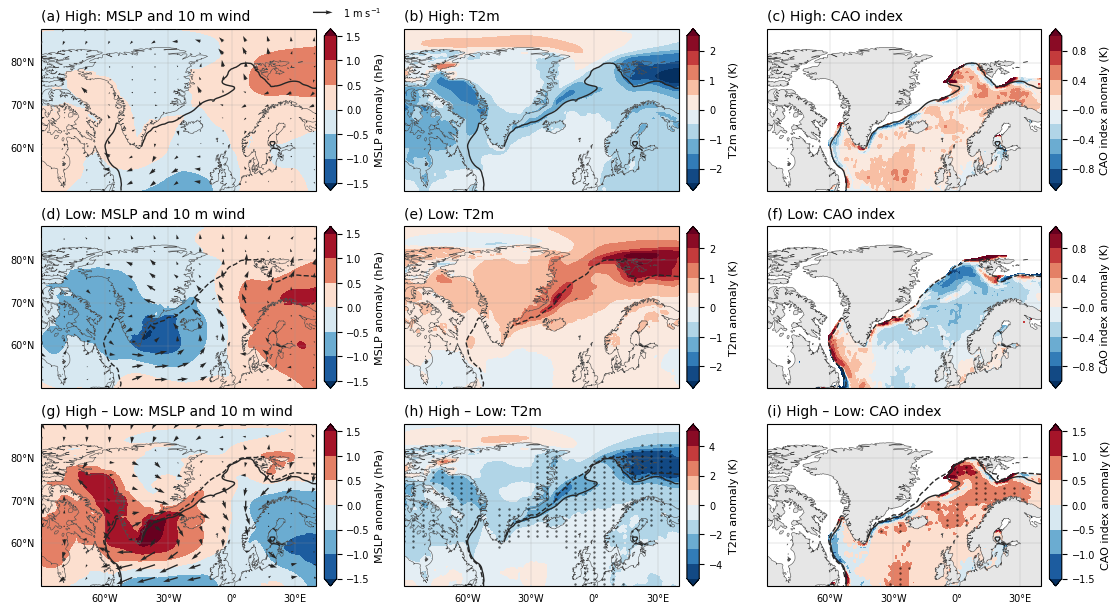

In [6]:
def nice_levels(lim, target_n=10):
    if not np.isfinite(lim) or lim <= 0:
        lim = 1.0
    raw_step = 2 * lim / target_n
    mag = 10 ** np.floor(np.log10(raw_step))
    res = raw_step / mag
    step = (1 if res <= 1 else 2 if res <= 2 else 5 if res <= 5 else 10) * mag
    vmax = np.ceil(lim / step) * step
    return np.arange(-vmax, vmax + step / 2, step)


def _colorbar(ax, im, label):
    cax = ax.inset_axes([1.03, 0.0, 0.045, 1.0], transform=ax.transAxes)
    cb = plt.colorbar(im, cax=cax, orientation='vertical')
    cb.set_label(label, fontsize=CBAR_LABEL_FONTSIZE)
    cb.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)


def _stipple(ax, lon, lat, pvalue, target_points=28):
    ny, nx = pvalue.shape
    sky, skx = max(1, ny // target_points), max(1, nx // target_points)
    LO, LA = np.meshgrid(lon[::skx], lat[::sky])
    sig = pvalue[::sky, ::skx] < 0.05
    if sig.any():
        ax.scatter(LO[sig], LA[sig], s=3.0, c='k', alpha=0.6, linewidths=0,
                   transform=ccrs.PlateCarree(), zorder=5)


def _figsize(extent, ncols, nrows, panel_width=4.0, max_aspect=2.0):
    lon0, lon1, lat0, lat1 = extent
    aspect = min((lon1 - lon0) / (lat1 - lat0), max_aspect)
    ph = panel_width / aspect
    return (panel_width * ncols + 0.9, ph * nrows + 0.28 * nrows + 0.4)


def plot_figure_07(composites, ice_edge, cols=ERA5_COLUMNS):
    extent = [ERA5_DOMAIN['lon'][0], ERA5_DOMAIN['lon'][1],
              ERA5_DOMAIN['lat'][0], ERA5_DOMAIN['lat'][1]]
    ncols = len(cols)
    fig = plt.figure(figsize=_figsize(extent, ncols, 3))
    gs = gridspec.GridSpec(3, ncols, figure=fig, hspace=0.22, wspace=0.32)

    for ci, (fname, cblabel, scale) in enumerate(cols):
        res = composites[fname]
        lon, lat = res['lon'], res['lat']
        hl_levels = nice_levels(np.nanpercentile(np.abs(np.concatenate(
            [(res['mean_high'] * scale).ravel(), (res['mean_low'] * scale).ravel()])), 98))
        diff_levels = nice_levels(np.nanpercentile(np.abs(res['diff'] * scale), 98))

        for ri, (key, levels) in enumerate([
                ('mean_high', hl_levels), ('mean_low', hl_levels), ('diff', diff_levels)]):
            ax = fig.add_subplot(gs[ri, ci], projection=ccrs.PlateCarree())
            ax.set_extent(extent, crs=ccrs.PlateCarree())
            ax.set_aspect('auto')
            ax.add_feature(cfeature.LAND, facecolor='0.9', zorder=0)
            ax.coastlines(resolution='50m', linewidth=0.4, color='0.3')
            gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.3, color='0.6', alpha=0.6,
                              xlocs=np.arange(-90, 41, 30), ylocs=np.arange(50, 89, 10),
                              draw_labels=True)
            gl.top_labels = gl.right_labels = False
            gl.left_labels = (ci == 0)
            gl.bottom_labels = (ri == 2)
            gl.xlabel_style = gl.ylabel_style = {'size': GRID_LABEL_FONTSIZE}

            im = ax.contourf(lon, lat, res[key] * scale, levels=levels, cmap='RdBu_r',
                             extend='both', transform=ccrs.PlateCarree())
            _colorbar(ax, im, cblabel)
            if key == 'diff':
                _stipple(ax, lon, lat, res['pvalue'])

            if key in ('mean_high', 'diff'):
                ax.contour(ice_edge['lon'], ice_edge['lat'], ice_edge['mean_high'],
                           levels=[SIC_THRESHOLD], colors='0.15', linewidths=1.0,
                           linestyles='solid', transform=ccrs.PlateCarree(), zorder=6)
            if key in ('mean_low', 'diff'):
                ax.contour(ice_edge['lon'], ice_edge['lat'], ice_edge['mean_low'],
                           levels=[SIC_THRESHOLD], colors='0.15', linewidths=1.0,
                           linestyles='dashed', transform=ccrs.PlateCarree(), zorder=6)

            if fname == 'msl':
                wu, wv = composites['u10'][key], composites['v10'][key]
                sky, skx = max(1, len(lat) // 12), max(1, len(lon) // 12)
                qv = ax.quiver(lon[::skx], lat[::sky], wu[::sky, ::skx], wv[::sky, ::skx],
                               transform=ccrs.PlateCarree(), scale=14, width=0.005,
                               color='0.15', zorder=4)
                if ri == 0:
                    ax.quiverkey(qv, 1.06, 1.10, WIND_QUIVERKEY_SPEED,
                                 f'{WIND_QUIVERKEY_SPEED:.0f} m s' + r'$^{-1}$',
                                 labelpos='E', coordinates='axes',
                                 fontproperties={'size': QUIVERKEY_FONTSIZE})

            letter = chr(ord('a') + ri * ncols + ci)
            col_title = COLUMN_TITLES.get(fname, cblabel.split(' anomaly')[0])
            ax.set_title(f'({letter}) {ROW_TITLES[key]}: {col_title}',
                         fontsize=TITLE_FONTSIZE, loc='left')
    return fig


fig = plot_figure_07(composites, ice_edge)
fig.savefig(FIG_PATH, dpi=DPI, bbox_inches='tight')
logger.info(f"Saved: {FIG_PATH}")
plt.show()

## Section 6 — Methods

In [7]:
r0 = composites['msl']
methods = f"""# Figure 7 — Atmospheric circulation and cold-air outbreak composites by sea-ice extent

## Classification
Greenland Sea winter-maximum sea-ice extent ({ICE_VAR}, OSI SAF SII v3), maximum of
monthly values over complete {'/'.join(str(m) for m in WINTER_MONTHS)} winters
(winters labelled by year of ending), restricted to winters with complete ERA5
coverage ({sie_max.index.min()}-{sie_max.index.max()}, n={len(sie_max)}).
High: upper quartile (>= {hi_thr:.3f}), n={len(high_years)}: {high_years}.
Low: lower quartile (<= {lo_thr:.3f}), n={len(low_years)}: {low_years}.

## Fields
ERA5 monthly means, {ERA5_DOMAIN}, native resolution. Anomalies relative to the
per-calendar-month climatology over {baseline_used.min()}-{baseline_used.max()}
(n={len(baseline_used)} years), then averaged to one winter (ONDJFMA) mean per year.
MSLP (hPa), 10 m wind (vectors), 2 m air temperature (K), and the CAO index
theta_skin - theta_{CAO_PRESSURE_LEVEL} (K, MetPy potential temperature,
p0 = 1000 hPa), masked where ERA5 siconc >= {SIC_THRESHOLD:.0%} before anomalising.

## Composites and significance
High and Low panels: mean of the winter-mean anomalies in each group; Diff = High - Low.
Stippling on Diff panels: p < 0.05, two-sided Welch's t-test with winters as the
sample unit (n_high={r0['n_high']}, n_low={r0['n_low']}), shown on a subsampled grid.
Contours: mean 15% ERA5 sea-ice concentration (raw, not anomaly) for High (solid)
and Low (dashed) winters; both shown on Diff panels.

## Panels
Titled '(letter) row: column', lettered row-wise: High a-c, Low d-f, High - Low g-i;
columns MSLP and 10 m wind, T2m, CAO index.
High and Low share one colour scale per column; Diff has its own.

## Caveat
Composites use undetrended extent. Median winter of the High group: {int(np.median(high_years))};
of the Low group: {int(np.median(low_years))}. Where these differ substantially, part of the
High - Low contrast (notably in T2m) reflects the long-term trend rather than circulation alone.

Figure: {FIG_PATH}
Data: {OUT_DATA / 'composite_stats_era5_GS_SIE.nc'}, {OUT_DATA / 'composite_classification_GS_SIE.csv'}
"""
(OUT_METH / 'figure_07_methodology.md').write_text(methods)
logger.info(f"Saved: {OUT_METH / 'figure_07_methodology.md'}")
print(methods)

INFO:figure_07:Saved: outputs/methods/figure_07_methodology.md


# Figure 7 — Atmospheric circulation and cold-air outbreak composites by sea-ice extent

## Classification
Greenland Sea winter-maximum sea-ice extent (ice_extent_greenland_monthly, OSI SAF SII v3), maximum of
monthly values over complete 10/11/12/1/2/3/4 winters
(winters labelled by year of ending), restricted to winters with complete ERA5
coverage (1980-2026, n=45).
High: upper quartile (>= 0.851), n=12: [1980, 1981, 1982, 1983, 1985, 1987, 1989, 1990, 1996, 1997, 1998, 2001].
Low: lower quartile (<= 0.675), n=12: [1994, 1999, 2003, 2006, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022].

## Fields
ERA5 monthly means, {'lon': (-90.0, 40.0), 'lat': (50.0, 88.0)}, native resolution. Anomalies relative to the
per-calendar-month climatology over 1979-2026
(n=48 years), then averaged to one winter (ONDJFMA) mean per year.
MSLP (hPa), 10 m wind (vectors), 2 m air temperature (K), and the CAO index
theta_skin - theta_850 (K, MetPy potential temperature,
p0 = 1000 hPa), masked where ERA5 sico